# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [1]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.013s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.013s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.12.1


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [3]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Overwriting Hello.java


In [4]:
!java Hello.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Среда готова, Java работает: 21.0.12.1


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [5]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Writing TariffBefore.java


In [6]:
!java TariffBefore.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [7]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Writing TariffAfter.java


In [8]:
!java TariffAfter.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [17]:
!apt-get -qq install -y plantuml > /dev/null && echo "PlantUML установлен"

PlantUML установлен


In [13]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


In [15]:
!apt-get update

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [82.1 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.6 MB]
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.9 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,154 kB]
Get:10 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,475 kB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,216 kB]
Get:13 http://security.ubunt

In [16]:
!apt-get install -y plantuml

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core default-jre default-jre-headless
  fonts-dejavu-core fonts-dejavu-extra fonts-dejavu-mono
  gsettings-desktop-schemas icc-profiles-free java-wrappers libapache-pom-java
  libatk-bridge2.0-0t64 libatk-wrapper-java libatk-wrapper-java-jni
  libatk1.0-0t64 libatspi2.0-0t64 libavalon-framework-java libbatik-java
  libcommons-io-java libcommons-logging-java libcommons-parent-java
  libfontbox2-java libfop-java libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libjaxp1.3-java libjlatexmath-java libqdox-java librsvg2-common
  libsaxon-java libxcomposite1 libxml-commons-external-java
  libxmlgraphics-commons-java libxtst6 libxxf86dga1 openjdk-21-jdk-headless
  openjdk-21-jre openjdk-21-jre-headless session-migration x11-utils
Suggested packages:
  libavalon-framework-java-doc librhino-java libcommons-io-java-doc
  libexca

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


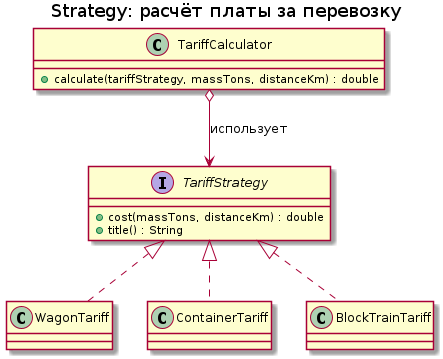

In [18]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   **Ответ:** В коде «до» пришлось бы менять сам метод cost в TariffBefore. В коде «после» — ничего менять не нужно, достаточно добавить новый класс-стратегию (в образце это анонимный класс refrigeratedTariff), старый код не трогается.
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   **Ответ:** legacyCost оставлен как эталон поведения для характеризующих тестов: проверяется, что новая реализация даёт те же числа, что и старая. После проверки его можно удалить.
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   **Ответ:**  Если в каталоге нет нужного ключа, tariffCatalog.get(...) вернёт null, и вызов tariffStrategy.cost(...) даст NullPointerException. Правильно — проверить наличие ключа (containsKey/getOrDefault) и явно бросить понятное исключение (например, IllegalArgumentException("неизвестный вид отправки")), либо вернуть Optional.

---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [19]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("COVERED", 68));
        System.out.println(describe("PLATFORM", 71));
        System.out.println(describe("TANK", 66));
        System.out.println(describe("HOPPER", 70));   // новый тип — обработчика нет
    }

    static String describe(String wagonType, double capacityTons) {
        if (wagonType.equals("COVERED")) {
            return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
        } else if (wagonType.equals("PLATFORM")) {
            return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
        } else if (wagonType.equals("TANK")) {
            return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
        }
        return "Неизвестный тип вагона: " + wagonType;
    }
}

Writing FactoryBefore.java


In [ ]:
!java FactoryBefore.java

### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [33]:
%%writefile FactoryAfter.java
// 3.3 Ваша реализация Factory Method
// Factory Method: создание вагона по типу через отдельных создателей.
import java.util.List;

public class FactoryAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        List<WagonCreator> creators = List.of(
            new CoveredWagonCreator(),
            new PlatformCreator(),
            new TankWagonCreator(),
            new HopperWagonCreator()
        );

        System.out.println("--- Все типы вагонов ---");
        for (WagonCreator creator : creators) {
            Wagon wagon = creator.createWagon(70);
            System.out.println(wagon.description());
        }

        System.out.println();
        System.out.println("--- Проверки ---");

        for (WagonCreator creator : creators) {
            Wagon wagon = creator.createWagon(70);
            check("описание содержит грузоподъёмность: " + wagon.description(),
                  wagon.description().contains("70"));
        }

        check("CoveredWagonCreator -> CoveredWagon",
              new CoveredWagonCreator().createWagon(68) instanceof CoveredWagon);
        check("PlatformCreator -> Platform",
              new PlatformCreator().createWagon(71) instanceof Platform);
        check("TankWagonCreator -> TankWagon",
              new TankWagonCreator().createWagon(66) instanceof TankWagon);
        check("HopperWagonCreator -> HopperWagon (четвёртый тип)",
              new HopperWagonCreator().createWagon(70) instanceof HopperWagon);

                failIfNeeded();
        System.out.println("Все проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) failedChecks++;
    }
        static void failIfNeeded() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
    }
}

// ---------- продукты ----------
interface Wagon {
    String description();
    double capacityTons();
}

class CoveredWagon implements Wagon {
    private final double capacityTons;
    CoveredWagon(double capacityTons) { this.capacityTons = capacityTons; }
    public String description() {
        return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
    }
    public double capacityTons() { return capacityTons; }
}

class Platform implements Wagon {
    private final double capacityTons;
    Platform(double capacityTons) { this.capacityTons = capacityTons; }
    public String description() {
        return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
    }
    public double capacityTons() { return capacityTons; }
}

class TankWagon implements Wagon {
    private final double capacityTons;
    TankWagon(double capacityTons) { this.capacityTons = capacityTons; }
    public String description() {
        return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
    }
    public double capacityTons() { return capacityTons; }
}

class HopperWagon implements Wagon {
    private final double capacityTons;
    HopperWagon(double capacityTons) { this.capacityTons = capacityTons; }
    public String description() {
        return "Зерновоз (хоппер): грузоподъёмность " + capacityTons + " т, сыпучие грузы";
    }
    public double capacityTons() { return capacityTons; }
}

// ---------- создатели ----------
abstract class WagonCreator {
    abstract Wagon createWagon(double capacityTons);
}

class CoveredWagonCreator extends WagonCreator {
    Wagon createWagon(double capacityTons) { return new CoveredWagon(capacityTons); }
}
class PlatformCreator extends WagonCreator {
    Wagon createWagon(double capacityTons) { return new Platform(capacityTons); }
}
class TankWagonCreator extends WagonCreator {
    Wagon createWagon(double capacityTons) { return new TankWagon(capacityTons); }
}
class HopperWagonCreator extends WagonCreator {
    Wagon createWagon(double capacityTons) { return new HopperWagon(capacityTons); }
}

Overwriting FactoryAfter.java


In [34]:
!java FactoryAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Все типы вагонов ---
Крытый вагон: грузоподъёмность 70.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 70.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 70.0 т, наливные грузы
Зерновоз (хоппер): грузоподъёмность 70.0 т, сыпучие грузы

--- Проверки ---
[OK]   описание содержит грузоподъёмность: Крытый вагон: грузоподъёмность 70.0 т, тарные и штучные грузы
[OK]   описание содержит грузоподъёмность: Платформа: грузоподъёмность 70.0 т, длинномерные и тяжеловесные грузы
[OK]   описание содержит грузоподъёмность: Цистерна: грузоподъёмность 70.0 т, наливные грузы
[OK]   описание содержит грузоподъёмность: Зерновоз (хоппер): грузоподъёмност

In [22]:
%%writefile factory.puml
@startuml
title Factory Method: создание вагона

interface Wagon {
  +description() : String
  +capacityTons() : double
}

abstract class WagonCreator {
  +createWagon(capacityTons) : Wagon
}

class CoveredWagon
class Platform
class TankWagon
class HopperWagon

class CoveredWagonCreator
class PlatformCreator
class TankWagonCreator
class HopperWagonCreator

Wagon <|.. CoveredWagon
Wagon <|.. Platform
Wagon <|.. TankWagon
Wagon <|.. HopperWagon

WagonCreator <|-- CoveredWagonCreator
WagonCreator <|-- PlatformCreator
WagonCreator <|-- TankWagonCreator
WagonCreator <|-- HopperWagonCreator

CoveredWagonCreator ..> CoveredWagon : создаёт
PlatformCreator ..> Platform : создаёт
TankWagonCreator ..> TankWagon : создаёт
HopperWagonCreator ..> HopperWagon : создаёт
WagonCreator ..> Wagon : возвращает
@enduml

Writing factory.puml


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


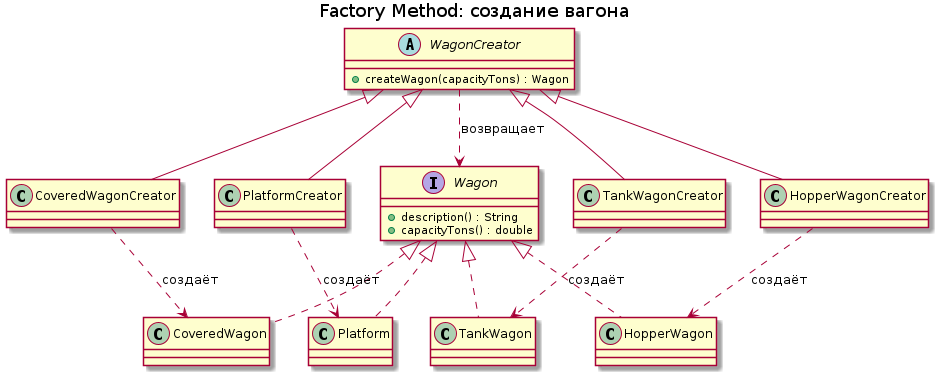

In [23]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

**Вывод по задаче 1** (чем создание через фабричный метод отличается от создания через `new` в вызывающем коде, и когда фабрика излишня): При создании через new в вызывающем коде (main) пришлось бы держать if/switch по типу вагона и менять main при каждом новом типе. Фабричный метод выносит решение «какой класс создать» в отдельный класс-создатель: main работает только с WagonCreator и Wagon, а четвёртый тип (зерновоз) добавлен новым классом HopperWagon + HopperWagonCreator без правки существующих классов. Фабрика излишня, когда продукт один и расширение не планируется — тогда лишний класс-создатель только усложняет код.

---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [24]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

Writing ObserverBefore.java


In [ ]:
!java ObserverBefore.java

### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [27]:
%%writefile ObserverAfter.java
// Observer: станция оповещает подписчиков о прибытии поезда.
// Вариант 1: событие трактуется как «вагон подан под погрузку»
// (номер поезда/вагона передаётся в trainNumber).
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        Station station = new Station("Гомель");

        BoardListener board = new BoardListener();
        JournalListener journal = new JournalListener();
        MailingListener mailing = new MailingListener();

        station.addListener(board);
        station.addListener(journal);
        station.addListener(mailing);

        System.out.println("--- Событие 1: поезд 3022 ---");
        station.trainArrived("3022");

        System.out.println();
        System.out.println("--- Проверки ---");

        // 1. После одного события журнал получил ровно одну запись
        check("журнал получил ровно одну запись", journal.getEntries().size() == 1);

        // 2. После отписки наблюдателя его записи больше не появляются
        station.removeListener(journal);
        station.trainArrived("6701");
        check("после отписки журнал не пополнился", journal.getEntries().size() == 1);

        // 3. Все подписчики получили одно и то же событие
        //    (табло и рассылка видели оба события, журнал — только первое)
        check("табло получило оба события", board.getEvents().size() == 2);
        check("рассылка получила оба события", mailing.getEvents().size() == 2);
        check("все получили одинаковое первое событие",
              board.getEvents().get(0).equals(mailing.getEvents().get(0))
              && board.getEvents().get(0).equals(journal.getEntries().get(0)));

        // 4. Четвёртый наблюдатель добавлен без правки Station
        AsuListener asu = new AsuListener();
        station.addListener(asu);
        station.trainArrived("8800");
        check("четвёртый наблюдатель (АСУ) получил событие", asu.getEvents().size() == 1);
        check("Station не знает про АСУ — он просто в списке наблюдателей",
              asu.getEvents().get(0).contains("8800"));

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) failedChecks++;
    }
}

// ---------- наблюдатель ----------
interface ArrivalListener {
    void onTrainArrived(String stationName, String trainNumber);
}

// ---------- субъект ----------
// Station НЕ знает, какие именно наблюдатели существуют.
class Station {

    private final String stationName;
    private final List<ArrivalListener> listeners = new ArrayList<>();

    Station(String stationName) {
        this.stationName = stationName;
    }

    void addListener(ArrivalListener listener) {
        listeners.add(listener);
    }

    void removeListener(ArrivalListener listener) {
        listeners.remove(listener);
    }

    void trainArrived(String trainNumber) {
        for (ArrivalListener listener : listeners) {
            listener.onTrainArrived(stationName, trainNumber);
        }
    }
}

// ---------- наблюдатели ----------
class BoardListener implements ArrivalListener {
    private final List<String> events = new ArrayList<>();
    public void onTrainArrived(String stationName, String trainNumber) {
        String event = stationName + ":" + trainNumber;
        events.add(event);
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
    }
    List<String> getEvents() { return events; }
}

class JournalListener implements ArrivalListener {
    private final List<String> entries = new ArrayList<>();
    public void onTrainArrived(String stationName, String trainNumber) {
        String entry = stationName + ":" + trainNumber;
        entries.add(entry);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
    List<String> getEntries() { return entries; }
}

class MailingListener implements ArrivalListener {
    private final List<String> events = new ArrayList<>();
    public void onTrainArrived(String stationName, String trainNumber) {
        String event = stationName + ":" + trainNumber;
        events.add(event);
        System.out.println("[рассылка] уведомление о поезде " + trainNumber + " на станции " + stationName);
    }
    List<String> getEvents() { return events; }
}

// Четвёртый наблюдатель — добавлен новым классом, Station не менялся
class AsuListener implements ArrivalListener {
    private final List<String> events = new ArrayList<>();
    public void onTrainArrived(String stationName, String trainNumber) {
        String event = stationName + ":" + trainNumber;
        events.add(event);
        System.out.println("[АСУ]     передано событие: " + event);
    }
    List<String> getEvents() { return events; }
}

Writing ObserverAfter.java


In [28]:
!java ObserverAfter.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Событие 1: поезд 3022 ---
[табло]  Поезд 3022 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 3022
[рассылка] уведомление о поезде 3022 на станции Гомель

--- Проверки ---
[OK]   журнал получил ровно одну запись
[табло]  Поезд 6701 прибыл на станцию Гомель
[рассылка] уведомление о поезде 6701 на станции Гомель
[OK]   после отписки журнал не пополнился
[OK]   табло получило оба события
[OK]   рассылка получила оба события
[OK]   все получили одинаковое первое событие
[табло]  Поезд 8800 прибыл на станцию Гомель
[рассылка] уведомление о поезде 8800 на станции Гомель
[АСУ]     передано событие: Гомель:8800
[OK]   четвёртый наблюдатель (АС

In [29]:
%%writefile observer.puml
@startuml
title Observer: оповещение о прибытии поезда

interface ArrivalListener {
  +onTrainArrived(stationName, trainNumber) : void
}

class Station {
  -stationName : String
  -listeners : List<ArrivalListener>
  +addListener(listener) : void
  +removeListener(listener) : void
  +trainArrived(trainNumber) : void
}

class BoardListener
class JournalListener
class MailingListener
class AsuListener

Station o--> ArrivalListener : оповещает
ArrivalListener <|.. BoardListener
ArrivalListener <|.. JournalListener
ArrivalListener <|.. MailingListener
ArrivalListener <|.. AsuListener
@enduml

Writing observer.puml


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


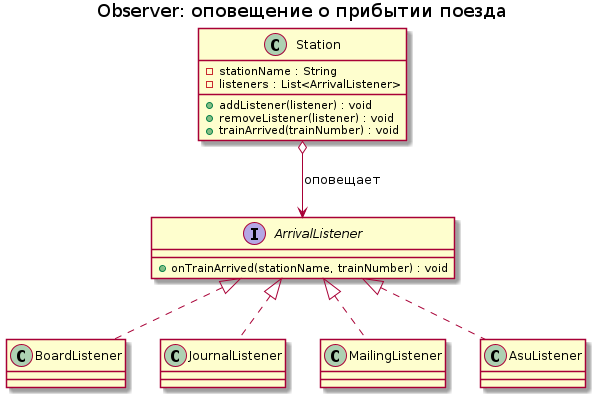

In [30]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

**Вывод по задаче 2** (какую связанность снял Observer и какие новые проблемы он создал — порядок уведомлений, ошибка в одном подписчике, забытая отписка): Observer снял жёсткую связь: Station больше не знает про табло, журнал и рассылку — она лишь обходит список ArrivalListener, поэтому четвёртый наблюдатель (АСУ) добавлен новым классом без правки Station. Порядок уведомлений равен порядку addListener и не отражает бизнес-приоритет. Исключение в одном подписчике прерывает обход остальных — нужен try/catch вокруг onTrainArrived. Забытая отписка (особенно у долгоживущего субъекта) держит ссылку и приводит к утечке памяти — нужно явно вызывать removeListener или использовать слабые ссылки.

---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Какую проблему кода «до» устраняет | Что добавляется без правки старого кода | Чем приходится заплатить | Где применим в вашем проекте |
|---|---|---|---|---|
| Strategy | if/else по виду отправки внутри одного метода расчёта |  новый класс-стратегия расчёта платы| лишний интерфейс и классы; вызывающий сам выбирает стратегию | расчёт платы за пользование вагонами |
| Factory Method | if/else по типу вагона при создании/описании | новый продукт + новый создатель (зерновоз) | иерархия создателей, больше классов | создание вагона нужного типа для подачи под погрузку |
| Observer | жёсткая связь станции с табло/журналом/рассылкой | новый наблюдатель (АСУ) без правки Station | порядок уведомлений, ошибка в одном подписчике, риск утечки из-за забытой отписки | оповещение о подаче вагона под погрузку (табло, журнал, рассылка, АСУ) |

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?
   **Ответ:** OCP (и SRP): метод сам и выбирает вариант, и делает работу. Strategy/Factory/Observer выносят выбор в отдельные классы — новый вариант добавляется новым классом, старый не меняется.
2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?
   **Ответ:** Factory Method — полиморфный (подклассы-создатели решают, что вернуть). Статический фабричный метод — просто static-метод без полиморфизма создателей. Abstract Factory — создаёт семейство связанных продуктов.
3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
   **Ответ:** Strategy — вызывающий выбирает алгоритм, алгоритмы не знают друг о друге. State — объект сам меняет поведение при смене внутреннего состояния, состояния знают о переходах.
4. Почему Observer может привести к утечке памяти и как этого избежать?
   **Ответ:** олгоживущий субъект держит ссылку на не отписавшегося наблюдателя → GC не соберёт → утечка. Лечится removeListener, WeakReference, AutoCloseable/try-with-resources.
5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?
   **Ответ:** Паттерн вреден, когда вариативности нет (один продукт/формула/получатель) — только лишние классы. Преждевременное усложнение — абстракции «на будущее» без подтверждённой потребности.

### 5.3 Три вывода по работе в целом

1. Паттерн нужен, чтобы убрать конкретную жёсткую связь; без кода «до» разница не видна.
2. Все три паттерна восстанавливают OCP: новое поведение — новым классом.
3. Цена паттерна — дополнительные классы и явный выбор/подписка; вводить только при реальной вариативности

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [ ] Раздел 1 выполнен, версия Java не ниже 11
- [ ] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [ ] Отвечены вопросы к образцу (п. 2.5)
- [ ] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [ ] Четвёртый тип вагона добавлен новым классом
- [ ] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [ ] Четвёртый наблюдатель добавлен без правки класса `Station`
- [ ] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [ ] Заполнена итоговая таблица (п. 5.1)
- [ ] Отвечены пять контрольных вопросов и сформулированы три вывода
- [ ] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [ ] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [35]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = "Аземша"  #@param {type:"string"}
Группа_исполнителя = "СИ-31"  #@param {type:"string"}
Номер_варианта = 1  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

### Отчёт самопроверки «Песочница паттернов GoF»

| Параметр | Значение |
|---|---|
| Исполнитель | Аземша, группа СИ-31, вариант 1 |
| Дата и время отчёта (UTC) | 2026-11-23 07:50 |
| Версия Java | openjdk version "21.0.13.1" 2026-11-17 |

| Программа | Файл | Результат |
|---|---|---|
| Образец, Strategy | `TariffAfter.java` | пройдено — проверок пройдено: 5 |
| Задача 1, Factory Method | `FactoryAfter.java` | пройдено — проверок пройдено: 8 |
| Задача 2, Observer | `ObserverAfter.java` | пройдено — проверок пройдено: 7 |

| Диаграммы | все три на месте |
| Таблица и выводы | заполнены |
| Замечания | нет |

Скопируйте отчёт выше в описание pull request.

Самопроверка пройдена: работа готова к сдаче.


---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |